<a href="https://colab.research.google.com/github/Mahtaj-zubaida/student-performance-prediction/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('student_performance_300.csv')

In [ ]:
df.head()

,Student_ID,Age,Gender,Study_Hours_Weekly,Attendance_Percent,Previous_Exam_Score,Assignments_Submitted_Percent,Sleep_Hours,Internet_Access,Performance
0,1,21,Female,4.9,74.9,78.3,100.0,7.4,Yes,Pass
1,2,18,Male,5.4,89.1,50.7,91.1,8.1,Yes,Pass
2,3,19,Female,4.1,78.2,52.4,90.2,6.3,No,Pass
3,4,21,Female,6.0,78.2,64.9,88.4,7.6,Yes,Pass
4,5,17,Female,1.5,88.5,75.4,73.5,6.7,Yes,Needs Support


In [ ]:
df.shape

(300, 10)

In [ ]:
df.isna().sum()

,0
Student_ID,0
Age,0
Gender,3
Study_Hours_Weekly,8
Attendance_Percent,7
Previous_Exam_Score,6
Assignments_Submitted_Percent,5
Sleep_Hours,4
Internet_Access,3
Performance,0


In [ ]:
df=df.bfill()
display(df.head())

,Student_ID,Age,Gender,Study_Hours_Weekly,Attendance_Percent,Previous_Exam_Score,Assignments_Submitted_Percent,Sleep_Hours,Internet_Access,Performance
0,1,21,Female,4.9,74.9,78.3,100.0,7.4,Yes,Pass
1,2,18,Male,5.4,89.1,50.7,91.1,8.1,Yes,Pass
2,3,19,Female,4.1,78.2,52.4,90.2,6.3,No,Pass
3,4,21,Female,6.0,78.2,64.9,88.4,7.6,Yes,Pass
4,5,17,Female,1.5,88.5,75.4,73.5,6.7,Yes,Needs Support


In [ ]:
df.isna().sum()

,0
Student_ID,0
Age,0
Gender,0
Study_Hours_Weekly,0
Attendance_Percent,0
Previous_Exam_Score,0
Assignments_Submitted_Percent,0
Sleep_Hours,0
Internet_Access,0
Performance,0


In [ ]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Study_Hours_Weekly',
       'Attendance_Percent', 'Previous_Exam_Score',
       'Assignments_Submitted_Percent', 'Sleep_Hours', 'Internet_Access',
       'Performance'],
      dtype='object')

In [ ]:
df['Performance'].value_counts().reset_index()

,Performance,count
0,Pass,150
1,Needs Support,150


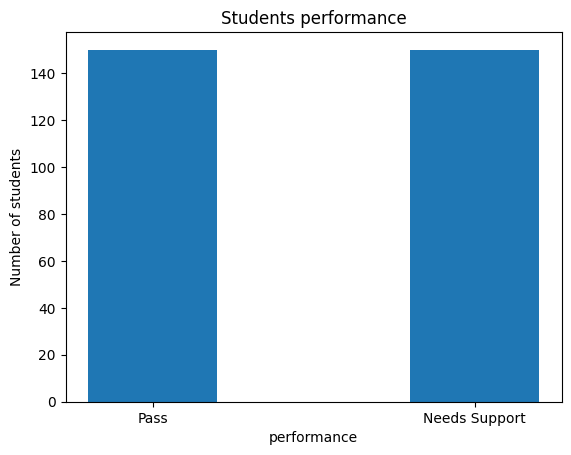

In [ ]:
plt.bar(df['Performance'].value_counts().index ,df['Performance'].value_counts().values,width=0.4)
plt.title('Students performance')
plt.xlabel('performance')
plt.ylabel('Number of students')
plt.show()

In [ ]:
students_performance=df.groupby('Study_Hours_Weekly')['Performance'].value_counts()
students_performance

,,count
Study_Hours_Weekly,Performance,
0.0,Needs Support,4
0.1,Needs Support,1
0.2,Needs Support,2
0.4,Needs Support,2
0.5,Needs Support,1
...,...,...
6.9,Pass,1
7.0,Pass,1
7.1,Pass,2


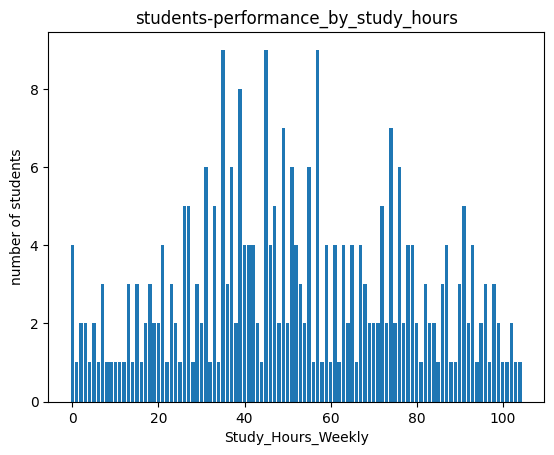

In [ ]:
plt.bar(range(len(students_performance)),students_performance.values)
plt.title('students-performance_by_study_hours')
plt.xlabel('Study_Hours_Weekly')
plt.ylabel('number of students')
plt.show()

In [ ]:
Attendance_distribution=df.groupby('Attendance_Percent')['Performance'].value_counts()
Attendance_distribution

,,count
Attendance_Percent,Performance,
50.1,Needs Support,1
52.2,Needs Support,1
53.6,Pass,1
54.1,Pass,1
54.2,Pass,1
...,...,...
98.2,Pass,1
98.6,Needs Support,1
98.7,Pass,1


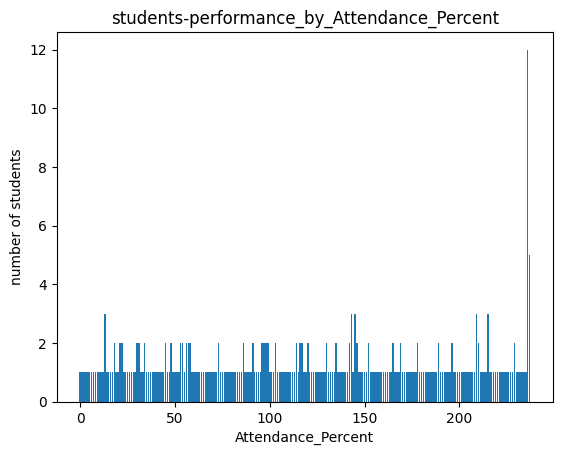

In [ ]:
plt.bar(range(len(Attendance_distribution)),Attendance_distribution.values)
plt.title('students-performance_by_Attendance_Percent')
plt.xlabel('Attendance_Percent')
plt.ylabel('number of students')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [ ]:
df.head(2)

,Student_ID,Age,Gender,Study_Hours_Weekly,Attendance_Percent,Previous_Exam_Score,Assignments_Submitted_Percent,Sleep_Hours,Internet_Access,Performance
0,1,21,Female,4.9,74.9,78.3,100.0,7.4,Yes,Pass
1,2,18,Male,5.4,89.1,50.7,91.1,8.1,Yes,Pass


In [ ]:
x=df.drop(columns=['Student_ID','Performance'])
y=df['Performance']
x=pd.get_dummies(x,drop_first=True,dtype=int)
display(x.head())

,Age,Study_Hours_Weekly,Attendance_Percent,Previous_Exam_Score,Assignments_Submitted_Percent,Sleep_Hours,Gender_Male,Internet_Access_Yes
0,21,4.9,74.9,78.3,100.0,7.4,0,1
1,18,5.4,89.1,50.7,91.1,8.1,1,1
2,19,4.1,78.2,52.4,90.2,6.3,0,0
3,21,6.0,78.2,64.9,88.4,7.6,0,1
4,17,1.5,88.5,75.4,73.5,6.7,0,1


In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,train_size=0.8 ,random_state=42)

In [ ]:
model_1=DecisionTreeClassifier(criterion='gini', max_depth=3, min_samples_leaf=3, random_state=42)
model_1.fit(x_train,y_train)
print("Model Training Completed Successfully!")


from sklearn.metrics import accuracy_score

y_pred = model_1.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Training Completed Successfully!
Model Accuracy: 0.75
Accuracy Percentage: 75.0 %


In [ ]:
y_prediction=model_1.predict(x_test)
print(y_prediction)

['Pass' 'Pass' 'Needs Support' 'Needs Support' 'Pass' 'Needs Support'
 'Needs Support' 'Pass' 'Needs Support' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass'
 'Pass' 'Pass' 'Pass' 'Needs Support' 'Needs Support' 'Pass'
 'Needs Support' 'Pass' 'Needs Support' 'Needs Support' 'Pass' 'Pass'
 'Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Needs Support'
 'Needs Support' 'Needs Support' 'Needs Support' 'Needs Support'
 'Needs Support' 'Pass' 'Pass' 'Needs Support' 'Needs Support'
 'Needs Support' 'Pass' 'Needs Support' 'Pass' 'Needs Support' 'Pass'
 'Needs Support' 'Needs Support' 'Pass' 'Pass' 'Pass' 'Pass'
 'Needs Support' 'Pass' 'Needs Support' 'Pass' 'Pass']


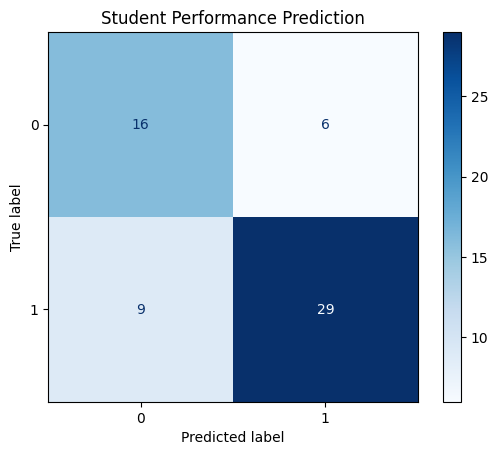

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model_1.predict(x_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title('Student Performance Prediction')
plt.show()

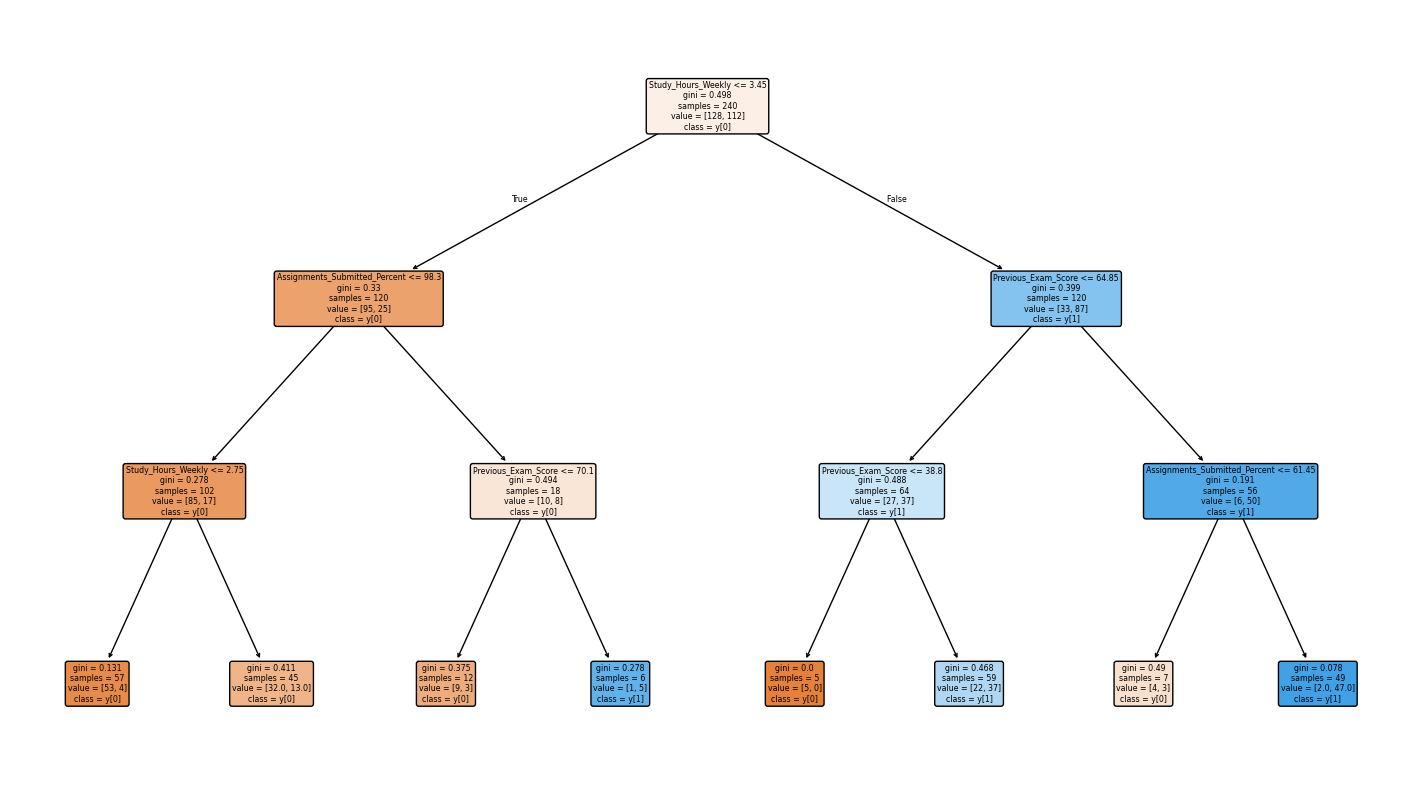

In [ ]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18,10))

tree.plot_tree(
    model_1,
    filled=True,
    feature_names=x_train.columns,
    class_names=True,
    rounded=True
)

plt.savefig('Decision_Tree.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
df.isna().sum()

df = df.bfill()

x = df.drop(columns=['Student_ID', 'Performance'])

y = df['Performance']

x = pd.get_dummies(x, drop_first=True, dtype=int)
print("Data Preprocessing Completed Successfully!")

print("Features shape:", x.shape)

Data Preprocessing Completed Successfully!
Features shape: (300, 8)
